# Phase 3 — Analyse exploratoire orientée insights

**Objectif :** comprendre *qui* part et *pourquoi*, pour en tirer des **insights actionnables** : chiffrés, confirmés statistiquement et reliés à une action de rétention.

**Plan**
1. Taux de churn par segment (variables catégorielles)
2. Variables numériques : ancienneté et facturation
3. Tests statistiques et classement des facteurs
4. Segments croisés et revenu à risque
5. Synthèse : les 5 insights clés

> ⚠️ **Corrélation ≠ causalité.** L'EDA met en évidence des *associations*. Par exemple, les clients en contrat mensuel sont aussi plus récents : il faut croiser les variables avant de conclure (section 4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.config import CATEGORICAL_COLS, NUMERIC_COLS, TARGET
from churn.data import load_clean
from churn.eda import churn_rate_table, categorical_association, numeric_association
from churn.viz import (set_style, save_fig, plot_churn_rate, fmt_pct,
                       BLUE, ORANGE, CHURN_COLORS, CHURN_LABELS, TEXT, TEXT_SECONDARY, GRID)

set_style()
df = load_clean()
GLOBAL_RATE = df[TARGET].mean()
print(f"{len(df)} clients — taux de churn global : {fmt_pct(GLOBAL_RATE)}")

7043 clients — taux de churn global : 26,5 %


## 1. Taux de churn par segment

Pour chaque modalité : le taux de churn (barre) comparé à la moyenne globale (ligne pointillée, 26,5 %). `n` = nombre de clients dans le segment.

### 1.1 Contrat et facturation

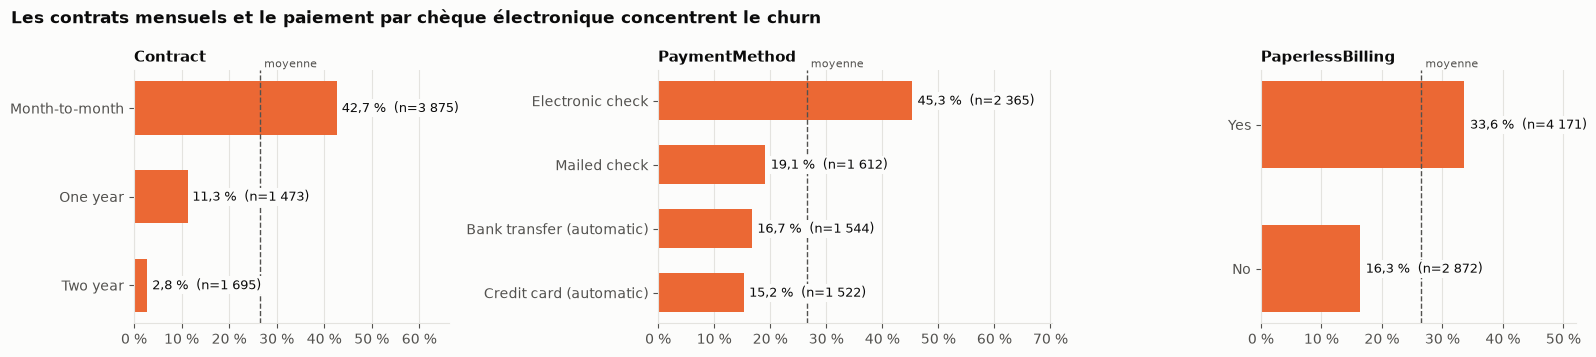

In [2]:
groups = {"Contrat et facturation": ["Contract", "PaymentMethod", "PaperlessBilling"]}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1, 1.25, 1]})
for ax, col in zip(axes, groups["Contrat et facturation"]):
    plot_churn_rate(ax, churn_rate_table(df, col), col, GLOBAL_RATE)
fig.suptitle("Les contrats mensuels et le paiement par chèque électronique concentrent le churn",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_churn_contrat_facturation.png")
plt.show()

In [3]:
churn_rate_table(df, "Contract").style.format({"churn_rate": "{:.1%}", "share": "{:.1%}", "lift": "{:.2f}"})

,clients,churners,churn_rate,share,lift
Contract,,,,,
Month-to-month,3875,1655,42.7%,55.0%,1.61
One year,1473,166,11.3%,20.9%,0.42
Two year,1695,48,2.8%,24.1%,0.11


**Lecture :**
- **Contrat** : c'est le facteur le plus spectaculaire. 42,7 % de churn en contrat mensuel contre **2,8 %** en contrat 2 ans, soit **15 fois moins**. Le contrat mensuel concerne 55 % des clients.
- **Paiement** : le **chèque électronique** atteint 45,3 % de churn, contre 15 à 19 % pour les autres moyens. Les deux paiements **automatiques** sont les plus fidèles : le client n'a pas à « décider » de payer chaque mois.
- **Facture dématérialisée** : 33,6 % contre 16,3 %. Probablement un **effet indirect** : ce sont des profils plus connectés, souvent en fibre et en contrat mensuel (à vérifier en section 4).

### 1.2 Services souscrits

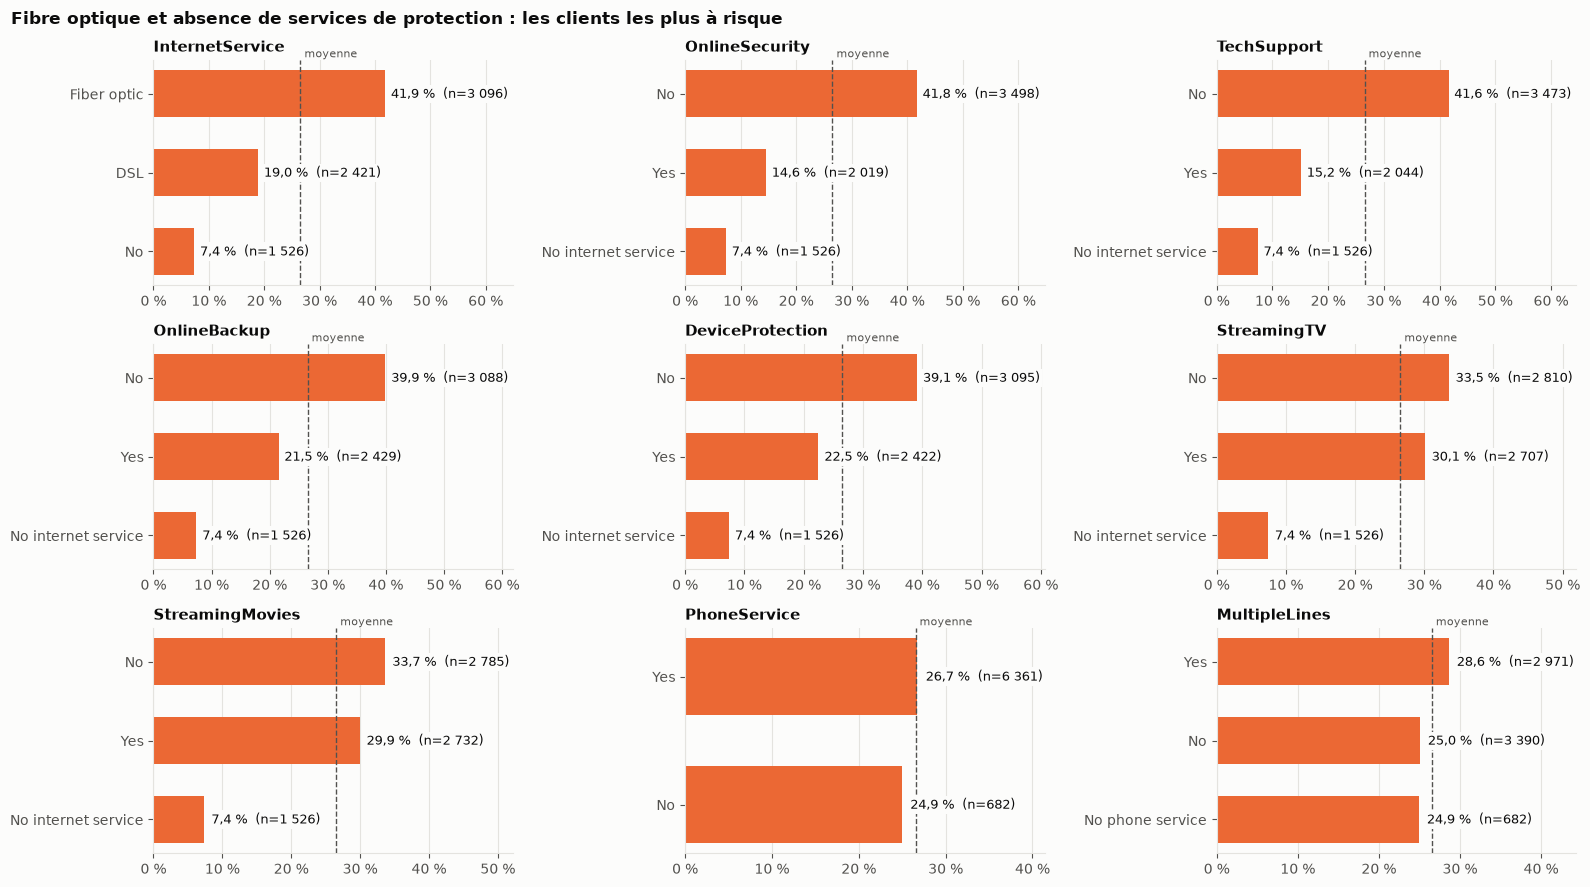

In [4]:
services = ["InternetService", "OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection",
            "StreamingTV", "StreamingMovies", "PhoneService", "MultipleLines"]
fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, services):
    plot_churn_rate(ax, churn_rate_table(df, col), col, GLOBAL_RATE)
fig.suptitle("Fibre optique et absence de services de protection : les clients les plus à risque",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_churn_services.png")
plt.show()

**Lecture :**
- **Fibre optique : 41,9 % de churn**, contre 19,0 % en DSL. Pourtant la fibre est l'offre « premium ». C'est un signal fort sur le **rapport qualité/prix** ou la **concurrence** sur ce segment.
- **Services de protection et d'assistance** (`OnlineSecurity`, `TechSupport`, `OnlineBackup`, `DeviceProtection`) : les clients **sans** ces services partent environ **2 à 3 fois plus**. Ces services créent de l'attachement et réduisent les frictions.
- **Streaming** : effet faible (33 % contre 30 %). Ce n'est pas un levier de rétention.
- **Téléphone** : aucun effet notable. Le churn se joue sur **l'internet**.
- Les clients **sans internet** sont les plus fidèles (7,4 %) : offre simple, peu chère, peu de raisons de comparer.

### 1.3 Profil client

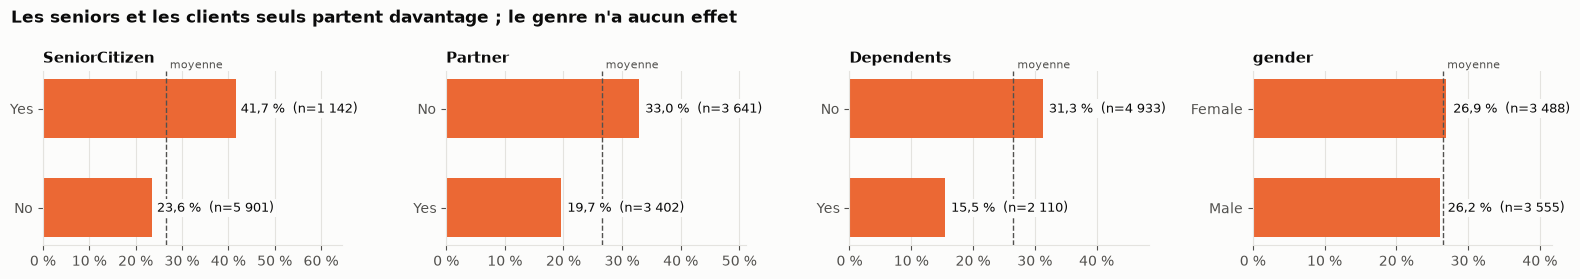

In [5]:
profile = ["SeniorCitizen", "Partner", "Dependents", "gender"]
fig, axes = plt.subplots(1, 4, figsize=(16, 2.8))
for ax, col in zip(axes, profile):
    plot_churn_rate(ax, churn_rate_table(df, col), col, GLOBAL_RATE)
fig.suptitle("Les seniors et les clients seuls partent davantage ; le genre n'a aucun effet",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_churn_profil.png")
plt.show()

**Lecture :**
- **Seniors** : 41,7 % contre 23,6 %. Un segment à accompagner (assistance, simplicité de l'offre).
- **Sans partenaire / sans personne à charge** : churn plus élevé. Un foyer « engage » davantage (offres familiales, coût du changement plus élevé).
- **Genre** : 26,9 % contre 26,2 %, **aucune différence**. C'est une bonne nouvelle pour l'éthique du modèle : la variable n'apporte rien et pourra être retirée (Phase 4).

## 2. Variables numériques

### 2.1 Distributions : partants vs restants

Les histogrammes sont **normalisés** (chaque groupe somme à 100 %) pour comparer des formes, et non des effectifs (il y a 2,8 fois plus de restants).

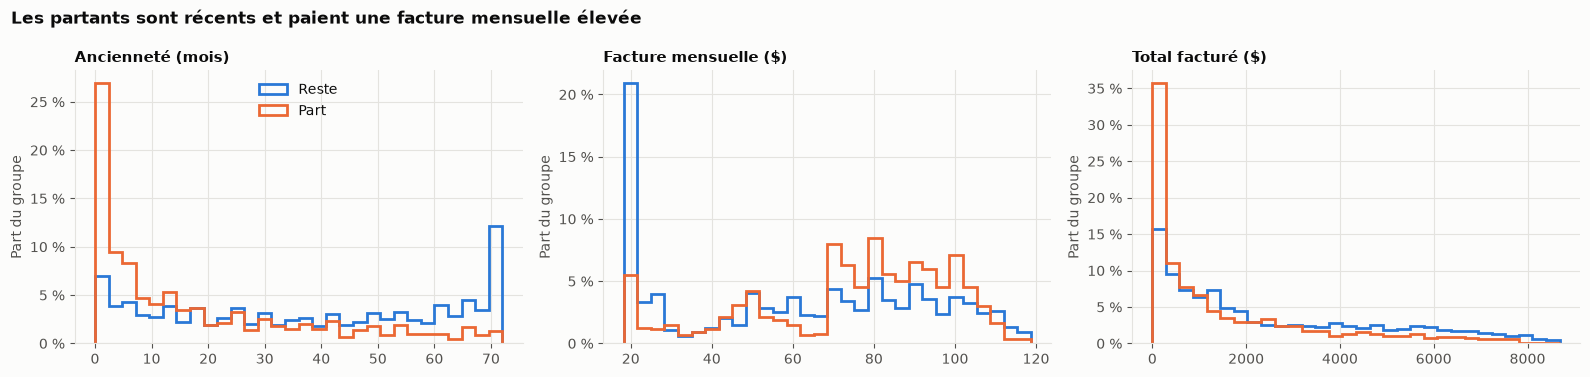

In [6]:
labels = {"tenure": "Ancienneté (mois)", "MonthlyCharges": "Facture mensuelle ($)", "TotalCharges": "Total facturé ($)"}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, NUMERIC_COLS):
    bins = np.histogram_bin_edges(df[col], bins=30)
    for value in (0, 1):
        subset = df.loc[df[TARGET] == value, col]
        ax.hist(subset, bins=bins, weights=np.full(len(subset), 1 / len(subset)),
                histtype="step", linewidth=2, color=CHURN_COLORS[value], label=CHURN_LABELS[value])
    ax.set_title(labels[col], fontsize=11)
    ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
    ax.set_ylabel("Part du groupe")
axes[0].legend(loc="upper center")
fig.suptitle("Les partants sont récents et paient une facture mensuelle élevée",
             x=0.01, ha="left", fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "03_distributions_part_reste.png")
plt.show()

In [7]:
numeric_association(df, NUMERIC_COLS).style.format(
    {"mediane_part": "{:.1f}", "mediane_reste": "{:.1f}", "p_value": "{:.1e}", "rank_biserial": "{:+.2f}"})

,mediane_part,mediane_reste,p_value,rank_biserial,significatif
variable,,,,,
tenure,10.0,38.0,2.4e-208,-0.48,True
TotalCharges,703.5,1679.5,5.7e-83,-0.30,True
MonthlyCharges,79.7,64.4,3.3e-54,+0.24,True


**Lecture :**
- **Ancienneté** : médiane de **10 mois** pour les partants, contre **38 mois** pour les restants. La courbe orange est massivement concentrée sur les premiers mois. C'est l'effet le plus fort des variables numériques (corrélation rang-bisériale −0,48).
- **Facture mensuelle** : médiane de **79,7 $** pour les partants contre 64,4 $. Les partants se concentrent entre 70 et 105 $ (les offres fibre), et les clients à ~20 $ (téléphone seul) partent très peu.
- **Total facturé** : plus faible chez les partants, mais c'est une **conséquence** de leur faible ancienneté (rappel Phase 2 : `TotalCharges ≈ tenure × MonthlyCharges`). Cette variable n'apporte pas d'information propre.

Le test de Mann-Whitney confirme que les trois écarts sont significatifs (p < 10⁻⁵⁰).

### 2.2 Zoom : le churn selon l'ancienneté

À quel moment de la relation client le risque est-il le plus élevé ?

In [8]:
tenure_bins = [-1, 6, 12, 24, 48, 72]
tenure_labels = ["0–6 mois", "7–12 mois", "13–24 mois", "25–48 mois", "49–72 mois"]
df_t = df.assign(tranche_anciennete=pd.cut(df["tenure"], tenure_bins, labels=tenure_labels))
by_tenure = churn_rate_table(df_t, "tranche_anciennete").reindex(tenure_labels)

churners_first_year = df.loc[df["tenure"] <= 12, TARGET].sum() / df[TARGET].sum()
print(f"Part des départs survenant la 1re année : {fmt_pct(churners_first_year)}")
by_tenure.style.format({"churn_rate": "{:.1%}", "share": "{:.1%}", "lift": "{:.2f}"})

Part des départs survenant la 1re année : 55,5 %


,clients,churners,churn_rate,share,lift
tranche_anciennete,,,,,
0–6 mois,1481,784,52.9%,21.0%,1.99
7–12 mois,705,253,35.9%,10.0%,1.35
13–24 mois,1024,294,28.7%,14.5%,1.08
25–48 mois,1594,325,20.4%,22.6%,0.77
49–72 mois,2239,213,9.5%,31.8%,0.36


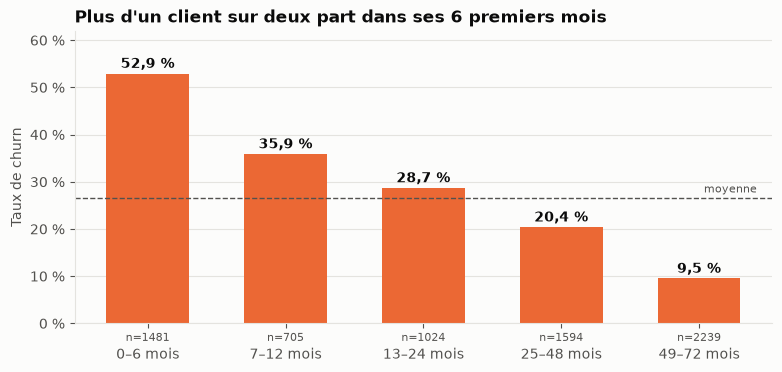

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(tenure_labels, by_tenure["churn_rate"], color=ORANGE, width=0.6)
for bar, rate, n in zip(bars, by_tenure["churn_rate"], by_tenure["clients"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012, fmt_pct(rate),
            ha="center", fontsize=10, color=TEXT, fontweight="bold")
    ax.text(bar.get_x() + bar.get_width() / 2, -0.06, f"n={n}", ha="center", fontsize=8,
            color=TEXT_SECONDARY, transform=ax.get_xaxis_transform())
ax.axhline(GLOBAL_RATE, color=TEXT_SECONDARY, lw=1, ls="--")
ax.text(4.42, GLOBAL_RATE + 0.012, "moyenne", ha="right", fontsize=8, color=TEXT_SECONDARY)
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", pad=14)
ax.set_ylabel("Taux de churn")
ax.set_title("Plus d'un client sur deux part dans ses 6 premiers mois")
save_fig(fig, "03_churn_anciennete.png")
plt.show()

**Lecture :** le risque **décroît fortement avec l'ancienneté**, de 52,9 % (0–6 mois) à 9,5 % (plus de 4 ans), et **55 % de tous les départs** ont lieu la première année.

**Action associée :** mettre en place un **programme d'accueil (onboarding)** sur les 6 premiers mois : appel de bienvenue, vérification de la qualité de service, proposition de passage en contrat annuel après 3 mois.

## 3. Tests statistiques et classement des facteurs

**Question :** les écarts observés sont-ils réels, ou pourraient-ils être dus au hasard ? Et lesquels sont les plus forts ?

- **Test du χ² d'indépendance** (variables catégorielles). H₀ : la variable est indépendante du churn.
- **Correction de Bonferroni** : on réalise 16 tests ; au seuil de 5 %, on s'attend à ~0,8 faux positif par hasard. On divise donc le seuil par 16.
- **V de Cramér** : la *force* du lien (0 = aucun, 1 = parfait). Repères usuels : 0,1 faible, 0,3 modéré, 0,5 fort. Avec 7 000 clients, presque tout devient « significatif » : c'est la **taille d'effet** qui dit si un lien compte.

In [10]:
assoc = categorical_association(df, CATEGORICAL_COLS)
alpha_bonferroni = 0.05 / len(CATEGORICAL_COLS)
assoc["significatif_bonferroni"] = assoc["p_value"] < alpha_bonferroni
print(f"Seuil corrigé de Bonferroni : {alpha_bonferroni:.4f}")
assoc.style.format({"chi2": "{:.1f}", "p_value": "{:.1e}", "cramers_v": "{:.3f}"})

Seuil corrigé de Bonferroni : 0.0031


,chi2,p_value,cramers_v,significatif,significatif_bonferroni
variable,,,,,
Contract,1184.6,5.9e-258,0.410,True,True
OnlineSecurity,850.0,2.7e-185,0.347,True,True
TechSupport,828.2,1.4e-180,0.343,True,True
InternetService,732.3,9.6e-160,0.322,True,True
PaymentMethod,648.1,3.7e-140,0.303,True,True
OnlineBackup,601.8,2.1e-131,0.292,True,True
DeviceProtection,558.4,5.5e-122,0.282,True,True
StreamingMovies,375.7,2.7e-82,0.231,True,True
StreamingTV,374.2,5.5e-82,0.231,True,True


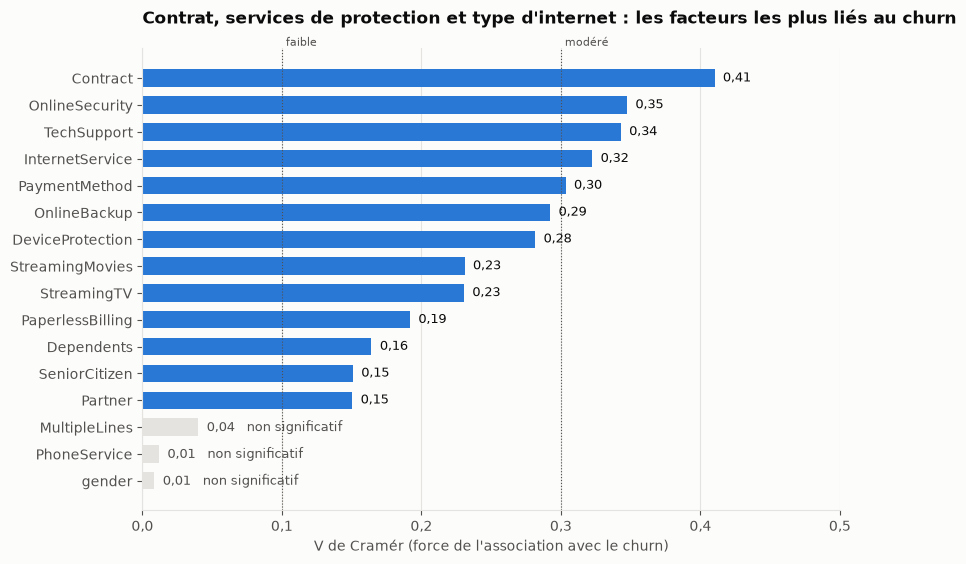

In [11]:
plot_data = assoc.sort_values("cramers_v")
colors = [BLUE if s else GRID for s in plot_data["significatif_bonferroni"]]
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(plot_data.index, plot_data["cramers_v"], color=colors, height=0.65)
for bar, v, sig in zip(bars, plot_data["cramers_v"], plot_data["significatif_bonferroni"]):
    label = f"{v:.2f}".replace(".", ",") + ("" if sig else "   non significatif")
    ax.text(bar.get_width() + 0.006, bar.get_y() + bar.get_height() / 2, label,
            va="center", fontsize=9, color=TEXT if sig else TEXT_SECONDARY)
for x, name in [(0.1, "faible"), (0.3, "modéré")]:
    ax.axvline(x, color=TEXT_SECONDARY, lw=0.8, ls=":")
    ax.text(x, 1.0, f" {name}", transform=ax.get_xaxis_transform(), fontsize=8,
            color=TEXT_SECONDARY, va="bottom")
ax.set_xlim(0, 0.5)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.1f}".replace(".", ","))
ax.grid(axis="y", visible=False)
ax.set_xlabel("V de Cramér (force de l'association avec le churn)")
ax.set_title("Contrat, services de protection et type d'internet : les facteurs les plus liés au churn", pad=18)
save_fig(fig, "03_classement_facteurs.png")
plt.show()

**Lecture :**
- **Facteurs modérés (V ≥ 0,3)** : `Contract` (0,41), `OnlineSecurity`, `TechSupport`, `InternetService`, `PaymentMethod`. Ce sont les leviers principaux.
- **Facteurs faibles mais réels** : les autres services de protection, la facturation dématérialisée, le profil du foyer, l'âge.
- **Non significatifs** : `gender` et `PhoneService` (p > 0,3), ainsi que `MultipleLines`, qui passe le seuil classique de 5 % (p = 0,0035) mais **échoue au seuil corrigé de Bonferroni** (0,0031). C'est un faux signal typique quand on multiplie les tests.

Côté numérique (section 2), l'**ancienneté** a l'effet le plus fort (rang-bisérial −0,48), devant la facture mensuelle (+0,24).

**Pour la Phase 4 :** `gender` et `PhoneService` sont candidates à la suppression. On le vérifiera par la performance du modèle, pas uniquement par ces tests univariés : une variable faible seule peut être utile en interaction.

## 4. Segments croisés et revenu à risque

Les analyses univariées peuvent être trompeuses si deux variables sont liées entre elles (**variables confondantes**). Exemple : les clients en contrat mensuel sont aussi plus récents. L'effet « contrat » n'est-il qu'un effet « ancienneté » déguisé ?

### 4.1 Contrat × ancienneté

In [12]:
contract_order = ["Month-to-month", "One year", "Two year"]
contract_colors = {"Month-to-month": "#86b6ef", "One year": "#2a78d6", "Two year": "#104281"}  # dégradé ordinal
cross_tenure = (df_t.groupby(["tranche_anciennete", "Contract"], observed=True)[TARGET]
                .agg(["mean", "size"]).unstack("Contract"))
cross_tenure["mean"].style.format("{:.1%}")

Contract,Month-to-month,One year,Two year
tranche_anciennete,,,
0–6 mois,55.2%,10.3%,0.0%
7–12 mois,42.0%,10.6%,0.0%
13–24 mois,37.7%,8.1%,0.0%
25–48 mois,32.9%,10.6%,2.2%
49–72 mois,26.0%,12.9%,3.3%


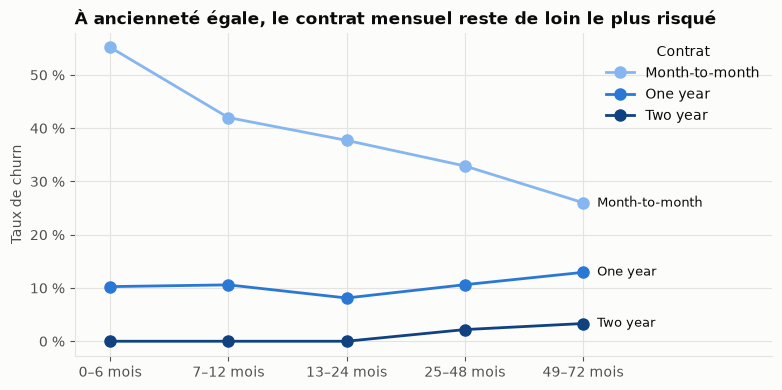

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(tenure_labels))
for contract in contract_order:
    rates = cross_tenure["mean"][contract].reindex(tenure_labels)
    ax.plot(x, rates, marker="o", markersize=8, lw=2, color=contract_colors[contract], label=contract)
    ax.text(x[-1] + 0.12, rates.iloc[-1], contract, va="center", fontsize=9, color=TEXT)
ax.set_xticks(x, tenure_labels)
ax.set_xlim(-0.3, len(x) - 0.3 + 0.9)
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.set_ylabel("Taux de churn")
ax.legend(loc="upper right", title="Contrat")
ax.set_title("À ancienneté égale, le contrat mensuel reste de loin le plus risqué")
save_fig(fig, "03_contrat_x_anciennete.png")
plt.show()

**Lecture :** dans **chaque tranche d'ancienneté**, le contrat mensuel churne nettement plus que les contrats d'un ou deux ans. L'effet du contrat **n'est pas qu'un effet d'ancienneté** : c'est un facteur à part entière. Les deux effets se **cumulent** : un client récent en contrat mensuel est le profil le plus risqué (55,2 % entre 0 et 6 mois).

*Précaution : les clients en contrat 1 ou 2 ans avec moins d'un an d'ancienneté sont rares (29 à 90 selon la tranche). Ces points sont moins précis, mais la conclusion reste nette vu l'ampleur des écarts.*

### 4.2 Contrat × type d'internet

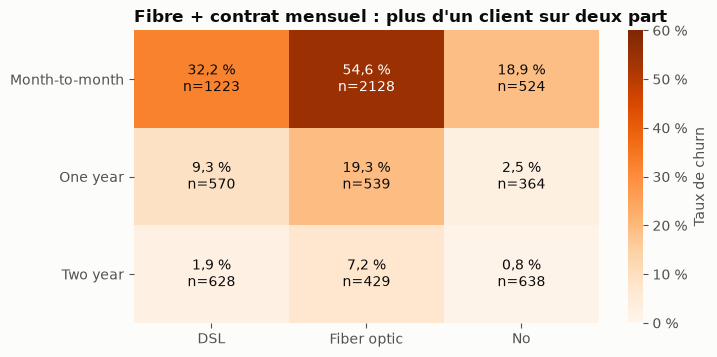

In [14]:
pivot_rate = pd.crosstab(df["Contract"], df["InternetService"], values=df[TARGET], aggfunc="mean")
pivot_n = pd.crosstab(df["Contract"], df["InternetService"])

fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(pivot_rate.values, cmap="Oranges", vmin=0, vmax=0.6, aspect="auto")
for i in range(pivot_rate.shape[0]):
    for j in range(pivot_rate.shape[1]):
        rate, n = pivot_rate.iat[i, j], pivot_n.iat[i, j]
        ax.text(j, i, f"{fmt_pct(rate)}\nn={n}", ha="center", va="center", fontsize=10,
                color="white" if rate > 0.35 else TEXT)
ax.set_xticks(range(pivot_rate.shape[1]), pivot_rate.columns)
ax.set_yticks(range(pivot_rate.shape[0]), pivot_rate.index)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig.colorbar(im, ax=ax, format=lambda v, _: fmt_pct(v, 0))
cbar.outline.set_visible(False)
cbar.set_label("Taux de churn", color=TEXT_SECONDARY)
ax.set_title("Fibre + contrat mensuel : plus d'un client sur deux part")
save_fig(fig, "03_contrat_x_internet.png")
plt.show()

**Lecture :** la fibre est plus risquée **quel que soit le contrat** (54,6 % contre 32,2 % pour le DSL en mensuel ; 7,2 % contre 1,9 % en 2 ans). Le segment **fibre + contrat mensuel** atteint **54,6 %** de churn sur 2 128 clients : c'est la **cible prioritaire**.

Hypothèse métier à vérifier avec l'opérateur : la fibre coûte en médiane ~92 $/mois contre ~56 $ pour le DSL. Ces clients sont plus exposés aux offres concurrentes et plus exigeants sur la qualité de service.

### 4.3 Effet « dose » des services de protection

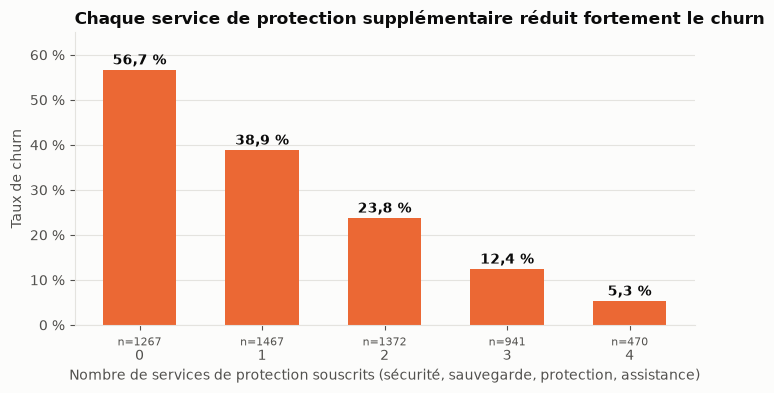

In [15]:
protection = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
internet_clients = df[df["InternetService"] != "No"].copy()
internet_clients["nb_protections"] = (internet_clients[protection] == "Yes").sum(axis=1)
by_prot = churn_rate_table(internet_clients, "nb_protections").sort_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(by_prot.index.astype(str), by_prot["churn_rate"], color=ORANGE, width=0.6)
for bar, rate, n in zip(bars, by_prot["churn_rate"], by_prot["clients"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012, fmt_pct(rate),
            ha="center", fontsize=10, fontweight="bold", color=TEXT)
    ax.text(bar.get_x() + bar.get_width() / 2, -0.07, f"n={n}", ha="center", fontsize=8,
            color=TEXT_SECONDARY, transform=ax.get_xaxis_transform())
ax.set_ylim(0, 0.65)
ax.tick_params(axis="x", pad=14)
ax.yaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Nombre de services de protection souscrits (sécurité, sauvegarde, protection, assistance)")
ax.set_ylabel("Taux de churn")
ax.set_title("Chaque service de protection supplémentaire réduit fortement le churn")
save_fig(fig, "03_effet_services_protection.png")
plt.show()

**Lecture :** chez les clients internet, le churn passe de **56,7 % sans aucun service de protection à 5,3 % avec les quatre**, avec une baisse régulière à chaque service ajouté. Cet effet « dose » est un argument fort pour un **levier commercial** : offrir 3 à 6 mois de `TechSupport` ou `OnlineSecurity` aux clients à risque.

⚠️ Effet de sélection possible : les clients qui souscrivent ces services sont peut-être déjà plus engagés. Seul un **test A/B** prouverait la causalité. C'est une recommandation à formuler à l'opérateur.

### 4.4 Où se concentre le revenu perdu ?

On valorise chaque départ à **12 mois de facture** (hypothèse de la Phase 0).

In [16]:
df_rev = df.assign(revenu_annuel=df["MonthlyCharges"] * 12)
churned = df_rev[df_rev[TARGET] == 1]
total_lost = churned["revenu_annuel"].sum()
print(f"Revenu annuel perdu (tous départs) : {total_lost:,.0f} $".replace(",", " "))

priority = (df_rev["Contract"] == "Month-to-month") & (df_rev["InternetService"] == "Fiber optic")
lost_priority = churned.loc[priority[churned.index], "revenu_annuel"].sum()
print(f"Dont segment fibre + mensuel : {lost_priority:,.0f} $".replace(",", " "))
shares = pd.Series({
    "Clients": priority.mean(),
    "Départs": df_rev.loc[priority, TARGET].sum() / df_rev[TARGET].sum(),
    "Revenu perdu": lost_priority / total_lost,
})
shares.map(fmt_pct)

Revenu annuel perdu (tous départs) : 1 669 570 $
Dont segment fibre + mensuel : 1 205 784 $


Clients         30,2 %
Départs         62,2 %
Revenu perdu    72,2 %
dtype: str

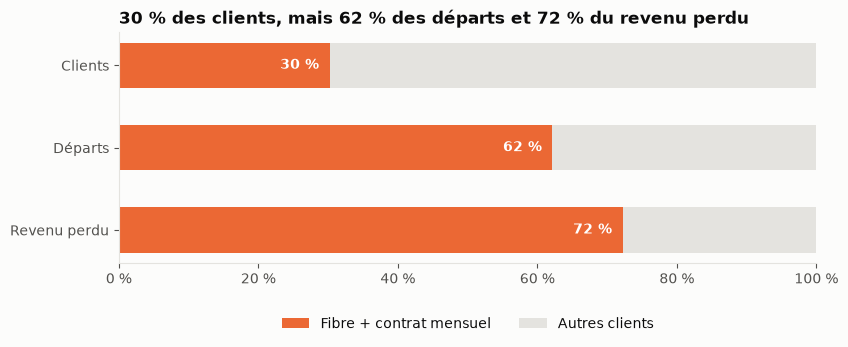

In [17]:
fig, ax = plt.subplots(figsize=(9, 3))
labels_rows = list(shares.index)[::-1]
values = shares[labels_rows]
ax.barh(labels_rows, values, color=ORANGE, height=0.55, label="Fibre + contrat mensuel")
ax.barh(labels_rows, 1 - values, left=values, color=GRID, height=0.55, label="Autres clients")
for i, v in enumerate(values):
    ax.text(v - 0.015, i, fmt_pct(v, 0), ha="right", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.set_title("30 % des clients, mais 62 % des départs et 72 % du revenu perdu")
save_fig(fig, "03_revenu_a_risque.png")
plt.show()

**Lecture :** le segment **fibre + contrat mensuel** représente **30 % des clients** mais **62 % des départs** et **72 % du revenu perdu** (~1,2 M$ sur ~1,67 M$). C'est là qu'une campagne de rétention a le plus d'impact.

## 5. Synthèse : les 5 insights clés

| # | Insight | Chiffre clé | Action de rétention recommandée |
|---|---|---|---|
| 1 | **Le contrat mensuel est le 1er facteur de churn**, indépendamment de l'ancienneté | 42,7 % contre 2,8 % en contrat 2 ans (×15) | Proposer une remise pour passer en contrat 1 ou 2 ans |
| 2 | **Les 6 premiers mois sont critiques** | 52,9 % de churn ; 55 % des départs ont lieu la 1re année | Programme d'onboarding : appel de bienvenue, suivi qualité à M+1 et M+3 |
| 3 | **Fibre + contrat mensuel = segment prioritaire** | 30 % des clients, 62 % des départs, 72 % du revenu perdu | Concentrer le budget de rétention sur ce segment ; auditer prix et qualité de la fibre |
| 4 | **Les services de protection fidélisent (effet dose)** | De 56,7 % (aucun service) à 5,3 % (4 services) | Offrir 3 à 6 mois de TechSupport / OnlineSecurity ; valider par test A/B |
| 5 | **Le paiement par chèque électronique signale un risque** | 45,3 % contre ~15 % en paiement automatique | Inciter au prélèvement automatique (petite remise, simplicité) |

**Non-facteurs :** le **genre** et le service **téléphonique** n'ont aucun lien avec le churn. C'est rassurant sur le plan éthique : le modèle n'aura pas besoin du genre pour bien prédire.

**Ce que ça implique pour la modélisation (Phase 4) :**
- Variables à fort potentiel : contrat, ancienneté, type d'internet, services de protection, moyen de paiement.
- Features à construire : nombre de services de protection, tranches d'ancienneté, indicateur « nouveau client ».
- Variables à retirer ou tester : `gender`, `PhoneService`, `TotalCharges` (redondante).